# ZeRO Distributed Training Simulation

This notebook demonstrates the memory and communication characteristics of Data Parallelism and ZeRO stages 1-3 for training a 30B parameter model.

Based on the concepts from **Session 12: Distributed Training I, Data Parallel and ZeRO**

In [ ]:
import sys

sys.path.insert(0, 'Users/admin/zero_sim')

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

from zero_sim.models.model import MemoryBreakdown, create_model_config
from zero_sim.simulation.runner import (
    run_communication_analysis,
    run_memory_scaling_analysis,
    run_simulation,
)
from zero_sim.simulation.zero_simulator import (
    DataParallelSimulator,
    ZeRO1Simulator,
    ZeRO2Simulator,
    ZeRO3Simulator,
)
from zero_sim.virtual_gpu.cluster import VirtualGPUCluster

sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)

## 1. Model Configuration & Theoretical Memory Breakdown

In [2]:
# Configure the model (30B parameters as per the PDF)
config = create_model_config(num_parameters=30_000_000_000, precision="fp16")
mem_breakdown = MemoryBreakdown.from_config(config)

print("Model Configuration:")
print(f"  Parameters: {config.num_parameters/1e9:.1f}B")
print(f"  Layers: {config.num_layers}")
print(f"  Hidden Size: {config.hidden_size}")
print(f"  Precision: {config.weight_dtype}")

print("\nTheoretical Memory Breakdown (per GPU, full model replica):")
for k, v in mem_breakdown.to_dict().items():
    print(f"  {k}: {v:.2f} GB")
print(f"  Total: {mem_breakdown.total_gb:.2f} GB")

print("\nGPU Memory (H100 80GB): 74.5 GiB usable")
print(f"Full model fits: {'YES' if mem_breakdown.total_gb <= 74.5 else 'NO'}")

Model Configuration:
  Parameters: 30.0B
  Layers: 48
  Hidden Size: 7168
  Precision: fp16

Theoretical Memory Breakdown (per GPU, full model replica):
  weight_gb: 60.00 GB
  gradient_gb: 60.00 GB
  fp32_weight_gb: 120.00 GB
  optimizer_state_gb: 240.00 GB
  total_gb: 480.00 GB
  Total: 480.00 GB

GPU Memory (H100 80GB): 74.5 GiB usable
Full model fits: NO


## 2. Run Simulation for 32 GPUs

In [3]:
results = run_simulation(
    world_size=32,
    model_params=30_000_000_000,
    precision="fp16",
    batch_size=2,
    seq_len=4096,
    memory_per_gpu_gb=74.5,
)


ZeRO SIMULATION: 30B Model, 32 GPUs
GPU Memory: 74.5 GB, Precision: fp16

Theoretical Memory (per GPU, full model):
  weight_gb: 60.00 GB
  gradient_gb: 60.00 GB
  fp32_weight_gb: 120.00 GB
  optimizer_state_gb: 240.00 GB
  total_gb: 480.00 GB
  Total: 480.00 GB

--- Running DP ---
  Memory/GPU:      491.27 GB
  Peak Memory/GPU: 491.27 GB
  Fits in GPU:     NO
  Comm Volume:     1920.00 GB
  Comm Time:       0.21 ms
  Compute Time:    300.00 ms
  Step Time:       300.21 ms

--- Running ZERO1 ---
  Memory/GPU:      142.52 GB
  Peak Memory/GPU: 142.52 GB
  Fits in GPU:     NO
  Comm Volume:     180.00 GB
  Comm Time:       0.50 ms
  Compute Time:    300.00 ms
  Step Time:       300.50 ms

--- Running ZERO2 ---
  Memory/GPU:      84.40 GB
  Peak Memory/GPU: 84.40 GB
  Fits in GPU:     NO
  Comm Volume:     180.00 GB
  Comm Time:       0.29 ms
  Compute Time:    300.00 ms
  Step Time:       300.29 ms

--- Running ZERO3 ---
  Memory/GPU:      26.27 GB
  Peak Memory/GPU: 26.27 GB
  Fits in 

## 3. Memory Scaling Analysis Across World Sizes

In [4]:
scaling_results = run_memory_scaling_analysis(
    model_params=30_000_000_000,
    precision="fp16",
    memory_per_gpu_gb=74.5,
)


MEMORY SCALING ANALYSIS: 30B Model
  World Size   8: DP= 480.0GB(✗) Z1= 165.0GB(✗) Z2= 112.5GB(✗) Z3=  60.0GB(✓)
  World Size  16: DP= 480.0GB(✗) Z1= 142.5GB(✗) Z2=  86.2GB(✗) Z3=  30.0GB(✓)
  World Size  32: DP= 480.0GB(✗) Z1= 131.2GB(✗) Z2=  73.1GB(✓) Z3=  15.0GB(✓)
  World Size  64: DP= 480.0GB(✗) Z1= 125.6GB(✗) Z2=  66.6GB(✓) Z3=   7.5GB(✓)
  World Size 128: DP= 480.0GB(✗) Z1= 122.8GB(✗) Z2=  63.3GB(✓) Z3=   3.8GB(✓)
  World Size 256: DP= 480.0GB(✗) Z1= 121.4GB(✗) Z2=  61.6GB(✓) Z3=   1.9GB(✓)


## 4. Visualize Memory Scaling

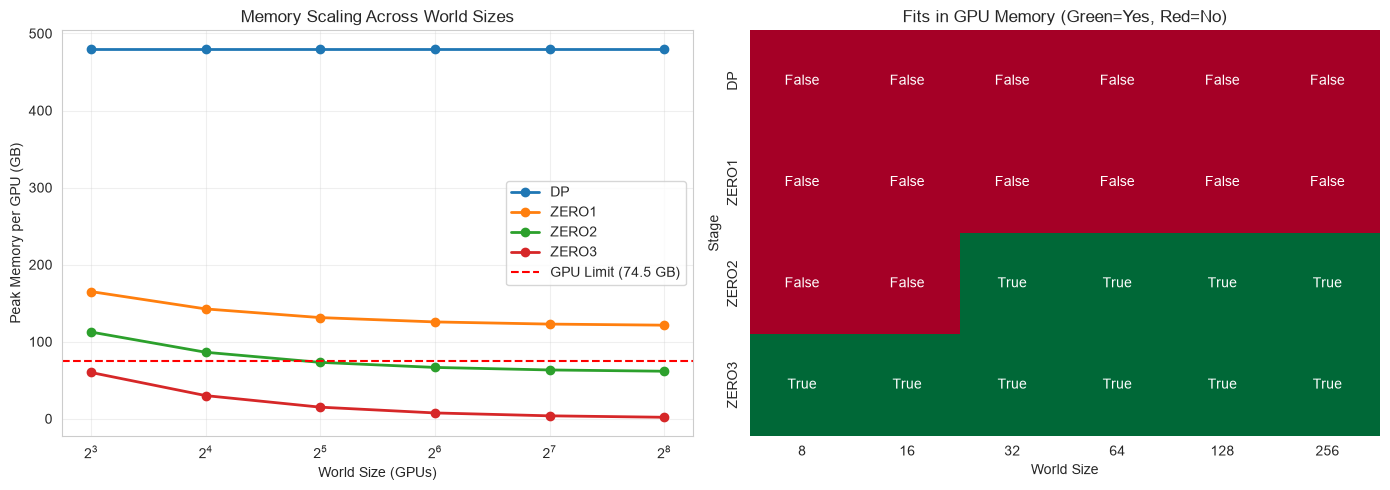

In [5]:
# Convert scaling results to DataFrame for plotting
data = []
for ws, stages in scaling_results.items():
    for stage, info in stages.items():
        data.append({
            "World Size": ws,
            "Stage": stage.upper(),
            "Peak Memory (GB)": info["peak_memory_gb"],
            "Fits": info["fits"]
        })

df = pd.DataFrame(data)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Memory vs World Size
for stage in df["Stage"].unique():
    stage_data = df[df["Stage"] == stage]
    axes[0].plot(stage_data["World Size"], stage_data["Peak Memory (GB)"],
                marker='o', label=stage, linewidth=2)

axes[0].axhline(y=74.5, color='r', linestyle='--', label='GPU Limit (74.5 GB)')
axes[0].set_xlabel("World Size (GPUs)")
axes[0].set_ylabel("Peak Memory per GPU (GB)")
axes[0].set_title("Memory Scaling Across World Sizes")
axes[0].set_xscale('log', base=2)
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Fit status heatmap
pivot = df.pivot(index="Stage", columns="World Size", values="Fits")
sns.heatmap(pivot, annot=True, fmt="", cmap="RdYlGn", cbar=False, ax=axes[1])
axes[1].set_title("Fits in GPU Memory (Green=Yes, Red=No)")

plt.tight_layout()
plt.show()

## 5. Communication Analysis

In [6]:
comm_results = run_communication_analysis(
    world_size=32,
    model_params=30_000_000_000,
    precision="fp16",
)


COMMUNICATION ANALYSIS: P = 60.0 GB
  Data Parallel  : 2P =  120.0 GB | NVLink:  266.7 ms | InfiniBand: 2400.0 ms
  ZeRO-1         : 2P =  120.0 GB | NVLink:  266.7 ms | InfiniBand: 2400.0 ms
  ZeRO-2         : 2P =  120.0 GB | NVLink:  266.7 ms | InfiniBand: 2400.0 ms
  ZeRO-3         : 3P =  180.0 GB | NVLink:  400.0 ms | InfiniBand: 3600.0 ms


## 6. Visualize Communication Volume

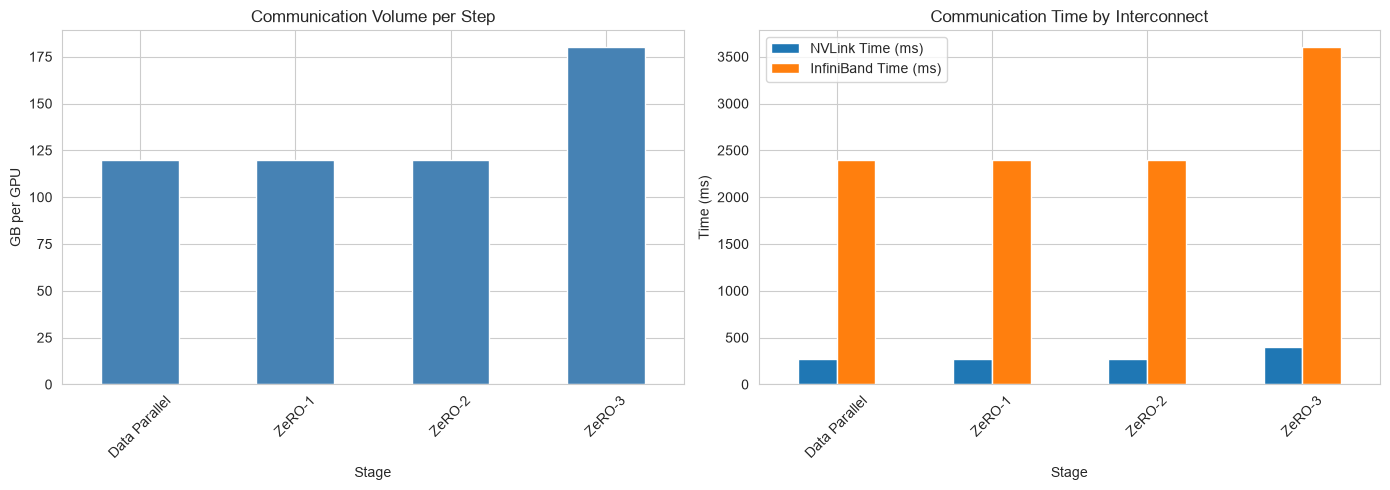

        Stage  Communication (GB)  Multiplier  NVLink Time (ms)  InfiniBand Time (ms)
Data Parallel               120.0           2        266.666667                2400.0
       ZeRO-1               120.0           2        266.666667                2400.0
       ZeRO-2               120.0           2        266.666667                2400.0
       ZeRO-3               180.0           3        400.000000                3600.0


In [7]:
comm_data = []
for name, info in comm_results.items():
    comm_data.append({
        "Stage": name,
        "Communication (GB)": info["comm_gb"],
        "Multiplier": info["multiplier"],
        "NVLink Time (ms)": info["nvlink_time_s"] * 1000,
        "InfiniBand Time (ms)": info["ib_time_s"] * 1000,
    })

comm_df = pd.DataFrame(comm_data)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

comm_df.plot(x="Stage", y="Communication (GB)", kind="bar", ax=axes[0], legend=False, color="steelblue")
axes[0].set_title("Communication Volume per Step")
axes[0].set_ylabel("GB per GPU")
axes[0].tick_params(axis='x', rotation=45)

comm_df.plot(x="Stage", y=["NVLink Time (ms)", "InfiniBand Time (ms)"], kind="bar", ax=axes[1])
axes[1].set_title("Communication Time by Interconnect")
axes[1].set_ylabel("Time (ms)")
axes[1].tick_params(axis='x', rotation=45)
axes[1].legend()

plt.tight_layout()
plt.show()

print(comm_df.to_string(index=False))

## 7. Compare Precision Impact (FP16 vs FP8)

In [8]:
print("="*60)
print("PRECISION IMPACT: FP16 vs FP8 (MXFP8)")
print("="*60)

for precision in ["fp16", "fp8"]:
    config = create_model_config(num_parameters=30_000_000_000, precision=precision)
    mem = MemoryBreakdown.from_config(config)
    print(f"\n{precision.upper()}:")
    for k, v in mem.to_dict().items():
        print(f"  {k}: {v:.2f} GB")
    print(f"  Total: {mem.total_gb:.2f} GB")
    print(f"  Reduction vs FP16: {(1 - mem.total_gb/447.0)*100:.1f}%" if precision == "fp8" else "")

PRECISION IMPACT: FP16 vs FP8 (MXFP8)

FP16:
  weight_gb: 60.00 GB
  gradient_gb: 60.00 GB
  fp32_weight_gb: 120.00 GB
  optimizer_state_gb: 240.00 GB
  total_gb: 480.00 GB
  Total: 480.00 GB


FP8:
  weight_gb: 30.00 GB
  gradient_gb: 30.00 GB
  fp32_weight_gb: 120.00 GB
  optimizer_state_gb: 240.00 GB
  total_gb: 420.00 GB
  Total: 420.00 GB
  Reduction vs FP16: 6.0%


## 8. Detailed Step-by-Step Simulation (Single Step)

Let's trace through a single training step for each stage to see the memory dynamics.

In [9]:

config = create_model_config(num_parameters=30_000_000_000, precision="fp16")
cluster = VirtualGPUCluster(world_size=8, memory_per_gpu_gb=74.5)

simulators = [
    DataParallelSimulator(cluster, config, batch_size=2, seq_len=4096),
    ZeRO1Simulator(cluster, config, batch_size=2, seq_len=4096),
    ZeRO2Simulator(cluster, config, batch_size=2, seq_len=4096),
    ZeRO3Simulator(cluster, config, batch_size=2, seq_len=4096),
]

for sim in simulators:
    print(f"\n{'='*50}")
    print(f"{sim.stage_name.upper()} - Step Trace (8 GPUs)")
    print(f"{'='*50}")

    cluster.reset_all()
    sim.setup()
    stats = cluster.get_cluster_stats()
    print("After Setup:")
    for gpu in stats.gpu_stats:
        print(f"  GPU {gpu['rank']}: {gpu['memory_allocated_gb']:.2f} GB - {gpu['tensors']}")

    forward_time = sim.forward_pass()
    stats = cluster.get_cluster_stats()
    print("\nAfter Forward:")
    for gpu in stats.gpu_stats:
        print(f"  GPU {gpu['rank']}: {gpu['memory_allocated_gb']:.2f} GB")

    backward_time = sim.backward_pass()
    stats = cluster.get_cluster_stats()
    print("\nAfter Backward:")
    for gpu in stats.gpu_stats:
        print(f"  GPU {gpu['rank']}: {gpu['memory_allocated_gb']:.2f} GB")

    opt_time = sim.optimizer_step()
    stats = cluster.get_cluster_stats()
    print("\nAfter Optimizer Step:")
    for gpu in stats.gpu_stats:
        print(f"  GPU {gpu['rank']}: {gpu['memory_allocated_gb']:.2f} GB")

    final_stats = sim.run_step()
    print(f"\nFinal: Peak={final_stats.peak_memory_per_gpu_gb:.2f}GB, Fits={final_stats.fits_in_memory}")


DP - Step Trace (8 GPUs)
After Setup:
  GPU 0: 480.00 GB - ['weights', 'gradients', 'fp32_weights', 'optimizer_state']
  GPU 1: 480.00 GB - ['weights', 'gradients', 'fp32_weights', 'optimizer_state']
  GPU 2: 480.00 GB - ['weights', 'gradients', 'fp32_weights', 'optimizer_state']
  GPU 3: 480.00 GB - ['weights', 'gradients', 'fp32_weights', 'optimizer_state']
  GPU 4: 480.00 GB - ['weights', 'gradients', 'fp32_weights', 'optimizer_state']
  GPU 5: 480.00 GB - ['weights', 'gradients', 'fp32_weights', 'optimizer_state']
  GPU 6: 480.00 GB - ['weights', 'gradients', 'fp32_weights', 'optimizer_state']
  GPU 7: 480.00 GB - ['weights', 'gradients', 'fp32_weights', 'optimizer_state']

After Forward:
  GPU 0: 491.27 GB
  GPU 1: 491.27 GB
  GPU 2: 491.27 GB
  GPU 3: 491.27 GB
  GPU 4: 491.27 GB
  GPU 5: 491.27 GB
  GPU 6: 491.27 GB
  GPU 7: 491.27 GB

After Backward:
  GPU 0: 491.27 GB
  GPU 1: 491.27 GB
  GPU 2: 491.27 GB
  GPU 3: 491.27 GB
  GPU 4: 491.27 GB
  GPU 5: 491.27 GB
  GPU 6: 491.2

## 9. Summary Table

In [10]:
summary_data = []
for stage_name in ["dp", "zero1", "zero2", "zero3"]:
    if stage_name in results:
        r = results[stage_name]
        summary_data.append({
            "Stage": stage_name.upper(),
            "Memory/GPU (GB)": f"{r['memory_per_gpu_gb']:.1f}",
            "Peak/GPU (GB)": f"{r['peak_memory_per_gpu_gb']:.1f}",
            "Fits": "✓" if r['fits_in_memory'] else "✗",
            "Comm (GB)": f"{r['total_communication_gb']:.1f}",
            "Comm Time (ms)": f"{r['communication_time_s']*1000:.1f}",
            "Step Time (ms)": f"{r['step_time_s']*1000:.1f}",
        })

summary_df = pd.DataFrame(summary_data)
print(summary_df.to_string(index=False))

Stage Memory/GPU (GB) Peak/GPU (GB) Fits Comm (GB) Comm Time (ms) Step Time (ms)
   DP           491.3         491.3    ✗    1920.0            0.2          300.2
ZERO1           142.5         142.5    ✗     180.0            0.5          300.5
ZERO2            84.4          84.4    ✗     180.0            0.3          300.3
ZERO3            26.3          26.3    ✓     180.0            0.4          300.4


## Key Takeaways

1. **Data Parallelism**: Replicates full model on every GPU. For 30B model (447 GB), needs 6+ 80GB GPUs just for model state. Doesn't fit on 8 GPUs with 74.5 GB each.

2. **ZeRO-1**: Partitions optimizer state (12/16 bytes per param). Reduces memory to ~154 GB/GPU at 8 GPUs. Still doesn't fit.

3. **ZeRO-2**: Partitions optimizer state + gradients (10/16 bytes). Reduces to ~105 GB/GPU at 8 GPUs. Fits at 32+ GPUs.

4. **ZeRO-3**: Partitions everything (weights, grads, optimizer). Only 2 bytes/param on GPU. Fits at 8 GPUs (56 GB/GPU).

5. **Communication Cost**: ZeRO-1/2 cost 2P (same as DP). ZeRO-3 costs 3P (extra all-gathers in forward/backward).

6. **Precision**: FP8 (MXFP8) reduces stored state by ~12%, but real gains are in compute speed and activation memory.

7. **Overlap**: Communication can be overlapped with computation using gradient bucketing (Section 10 of PDF).